# Step #1 Loading the Data

We use a fixed window of adjusted Coca-Cola (`KO`) closing prices so that the tutorial remains reproducible. Yahoo Finance can still revise historical prices after corporate actions.

In [1]:
import logging
import warnings
from importlib.metadata import version

warnings.filterwarnings("ignore", message="IProgress not found.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from prophet import Prophet
from prophet.plot import add_changepoints_to_plot
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

cmdstan_logger = logging.getLogger("cmdstanpy")
if not cmdstan_logger.handlers:
    cmdstan_logger.addHandler(logging.NullHandler())
cmdstan_logger.setLevel(logging.WARNING)
plt.style.use("seaborn-v0_8-whitegrid")

SYMBOL = "KO"
STOCK_NAME = "Coca-Cola"
START_DATE = "2015-01-01"
END_DATE = "2026-01-01"  # yfinance treats end as exclusive

prices = yf.download(
    SYMBOL,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    multi_level_index=False,
    progress=False,
)
if prices.empty:
    raise RuntimeError("Yahoo Finance returned no data. Check the connection and ticker.")

print(f"pandas {pd.__version__}, Prophet {version('prophet')}, yfinance {yf.__version__}")
prices.head()

pandas 3.0.3, Prophet 1.3.0, yfinance 1.5.1


,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,29.390268,29.571605,29.153137,29.473961,9921100
2015-01-05,29.390268,29.969148,29.348423,29.773862,26292600
2015-01-06,29.613449,29.948222,29.460013,29.578577,16897500
2015-01-07,29.983086,30.066778,29.697134,29.850570,13412300
2015-01-08,30.345758,30.387606,30.059807,30.115604,21743600


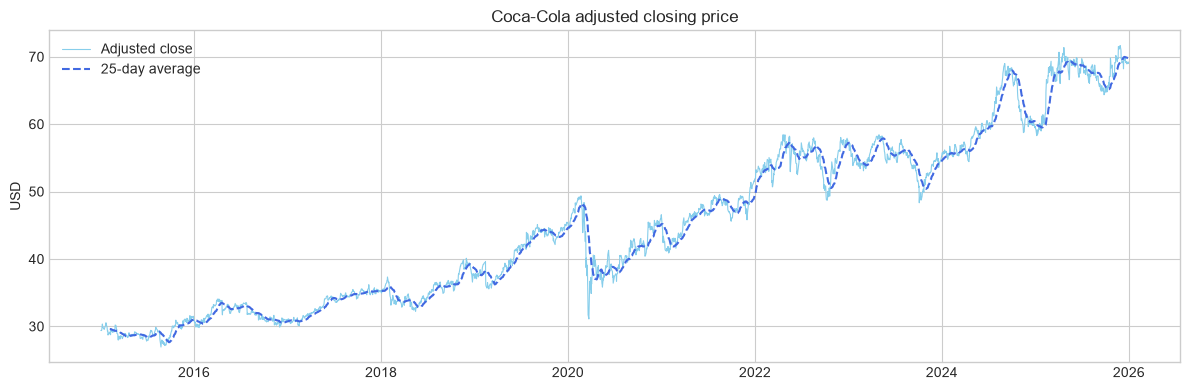

In [2]:
rolling_window = 25
moving_average = prices["Close"].rolling(rolling_window).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(prices.index, prices["Close"], color="skyblue", linewidth=0.8, label="Adjusted close")
ax.plot(prices.index, moving_average, color="royalblue", linestyle="--", label=f"{rolling_window}-day average")
ax.set(title=f"{STOCK_NAME} adjusted closing price", ylabel="USD", xlabel=None)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# Step #2 Prepare the Data

Prophet expects a `ds` timestamp column and a numeric `y` target. We reserve the last 126 observed market sessions as a chronological holdout before fitting the model.

In [3]:
HOLDOUT_SIZE = 126

prophet_data = (
    prices[["Close"]]
    .rename(columns={"Close": "y"})
    .rename_axis("ds")
    .reset_index()
    .dropna()
)
prophet_data["ds"] = pd.to_datetime(prophet_data["ds"]).dt.tz_localize(None)
prophet_data = prophet_data.sort_values("ds").drop_duplicates("ds").reset_index(drop=True)

if len(prophet_data) <= HOLDOUT_SIZE:
    raise ValueError("Not enough observations for the requested holdout.")

train_data = prophet_data.iloc[:-HOLDOUT_SIZE].copy()
test_data = prophet_data.iloc[-HOLDOUT_SIZE:].copy()
assert train_data["ds"].max() < test_data["ds"].min()

pd.DataFrame(
    {
        "rows": [len(prophet_data)],
        "train_end": [train_data["ds"].max().date()],
        "holdout_start": [test_data["ds"].min().date()],
        "holdout_end": [test_data["ds"].max().date()],
    }
)

,rows,train_end,holdout_start,holdout_end
0,2766,2025-07-02,2025-07-03,2025-12-31


# Step #3 Model Training and Backtesting

The model sees only the training period. We predict the actual holdout dates and compare Prophet with a constant forecast equal to the last training value.

In [4]:
RANDOM_SEED = 42
INTERVAL_WIDTH = 0.95


def fit_prophet(data, interval_width=INTERVAL_WIDTH, changepoint_range=0.8):
    model = Prophet(
        interval_width=interval_width,
        changepoint_range=changepoint_range,
        daily_seasonality=False,
    )
    return model.fit(data, seed=RANDOM_SEED)


backtest_model = fit_prophet(train_data)
np.random.seed(RANDOM_SEED)
test_forecast = backtest_model.predict(test_data[["ds"]])
evaluation = test_data.merge(
    test_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds",
    validate="one_to_one",
)
evaluation["last_value"] = train_data["y"].iloc[-1]

interval_coverage = evaluation["y"].between(
    evaluation["yhat_lower"], evaluation["yhat_upper"]
).mean()
metrics = pd.DataFrame(
    {
        "MAE": [
            mean_absolute_error(evaluation["y"], evaluation["yhat"]),
            mean_absolute_error(evaluation["y"], evaluation["last_value"]),
        ],
        "RMSE": [
            root_mean_squared_error(evaluation["y"], evaluation["yhat"]),
            root_mean_squared_error(evaluation["y"], evaluation["last_value"]),
        ],
        "95% interval coverage": [interval_coverage, np.nan],
    },
    index=["Prophet", "Last-value constant"],
)
metrics.round(1)

,MAE,RMSE,95% interval coverage
Prophet,2.0,2.4,0.9
Last-value constant,1.7,2.2,NaN


# Step #4 Analyzing the Forecast

The holdout plot shows errors on unseen observations. The requested 95% interval expresses Prophet's model uncertainty; its empirical coverage is measured above and is not guaranteed to equal 95%. We then refit on all observations and forecast 126 future weekdays.

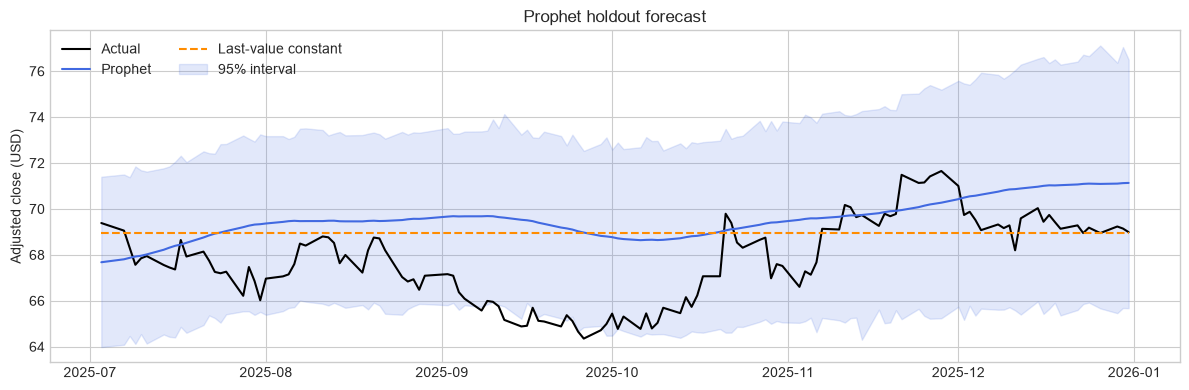

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
holdout_dates = evaluation["ds"].to_numpy()
ax.plot(holdout_dates, evaluation["y"], color="black", label="Actual")
ax.plot(holdout_dates, evaluation["yhat"], color="royalblue", label="Prophet")
ax.plot(
    holdout_dates,
    evaluation["last_value"],
    color="darkorange",
    linestyle="--",
    label="Last-value constant",
)
ax.fill_between(
    holdout_dates,
    evaluation["yhat_lower"].to_numpy(),
    evaluation["yhat_upper"].to_numpy(),
    color="royalblue",
    alpha=0.15,
    label="95% interval",
)
ax.set(title="Prophet holdout forecast", ylabel="Adjusted close (USD)", xlabel=None)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
plt.show()

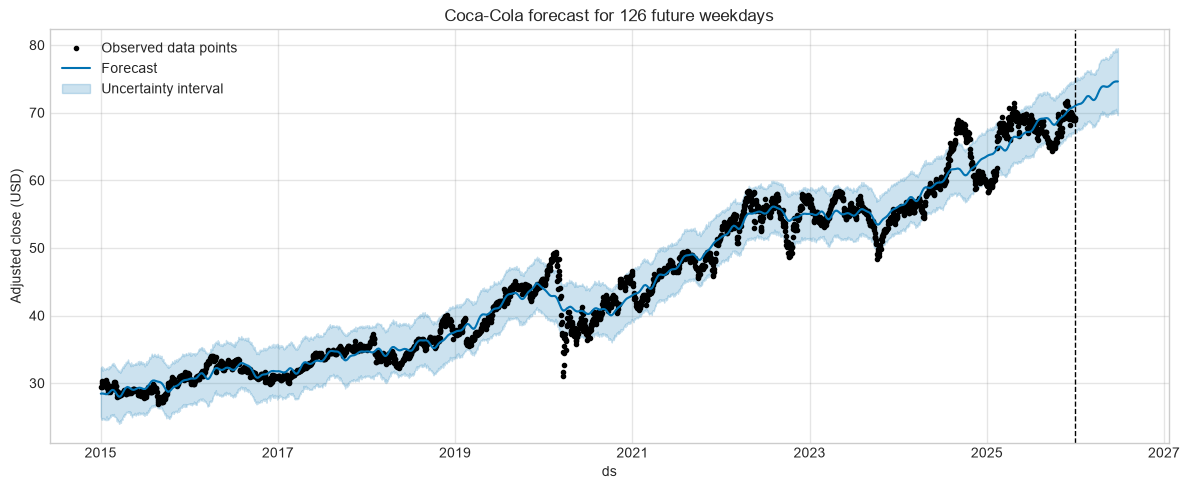

,ds,yhat_lower,yhat,yhat_upper
2887,2026-06-19,70.195311,74.612588,79.059585
2888,2026-06-22,69.801268,74.606123,79.452373
2889,2026-06-23,70.174208,74.632917,79.155027
2890,2026-06-24,69.619898,74.626959,79.306322
2891,2026-06-25,70.018110,74.614977,79.528252


In [6]:
FORECAST_PERIODS = 126

final_model = fit_prophet(prophet_data)
future_dates = final_model.make_future_dataframe(periods=FORECAST_PERIODS, freq="B")
np.random.seed(RANDOM_SEED)
forecast_df = final_model.predict(future_dates)
future_forecast = forecast_df.loc[
    forecast_df["ds"] > prophet_data["ds"].max(),
    ["ds", "yhat_lower", "yhat", "yhat_upper"],
].copy()

figure = final_model.plot(forecast_df, figsize=(12, 5), include_legend=True)
axis = figure.axes[0]
axis.axvline(prophet_data["ds"].max(), color="black", linestyle="--", linewidth=1)
axis.set(title=f"{STOCK_NAME} forecast for {FORECAST_PERIODS} future weekdays", ylabel="Adjusted close (USD)")
figure.tight_layout()
plt.show()

future_forecast.tail()

# Step #5 Analyzing Model Components

Prophet decomposes the fitted values into a trend and the seasonalities supported by the data. Weekend values in the weekly component are extrapolations because the stock-price history contains no weekend observations.

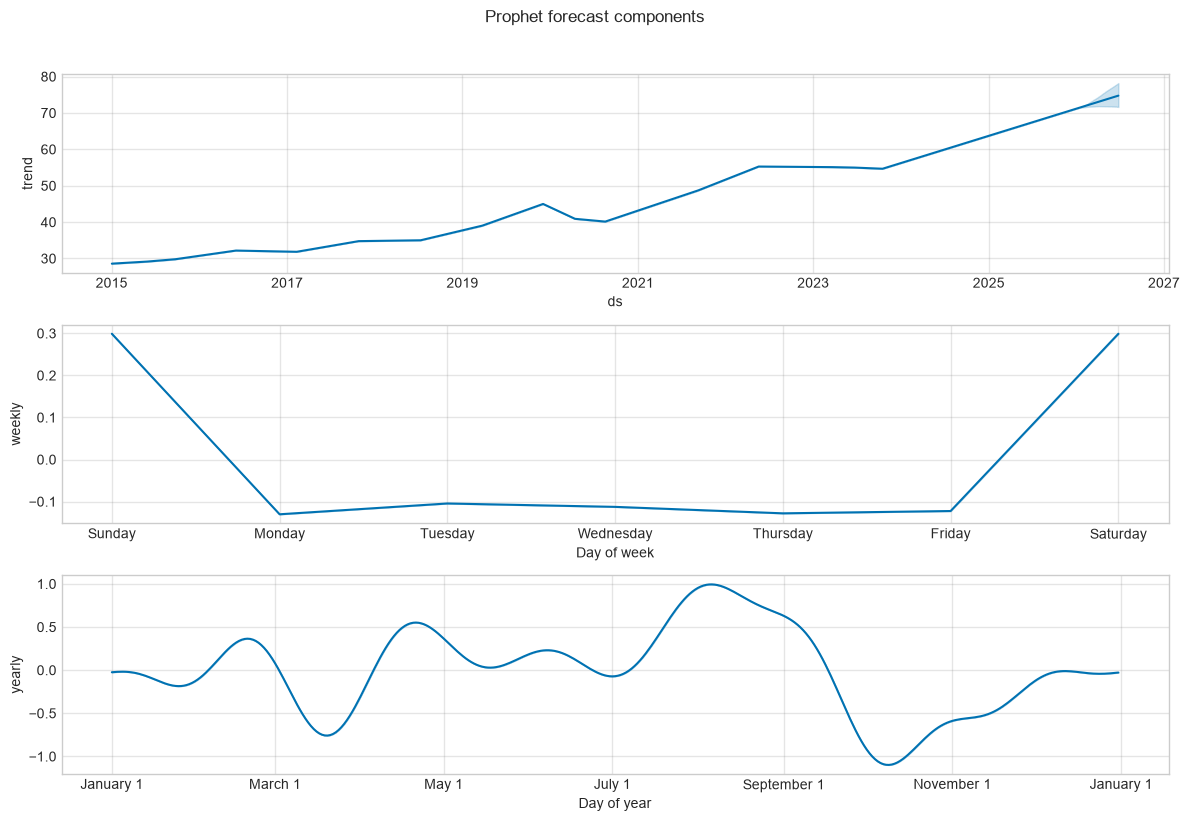

In [7]:
components_figure = final_model.plot_components(
    forecast_df,
    weekly_start=0,
    figsize=(12, 8),
)
components_figure.suptitle("Prophet forecast components", y=1.02)
components_figure.tight_layout()
plt.show()

# Step #6 Adjusting the Changepoint Window

By default, Prophet distributes 25 potential changepoints across the first 80% of the history. Setting `changepoint_range=1.0` extends that candidate window through the full history; it does not increase the number of candidates or guarantee a better forecast.

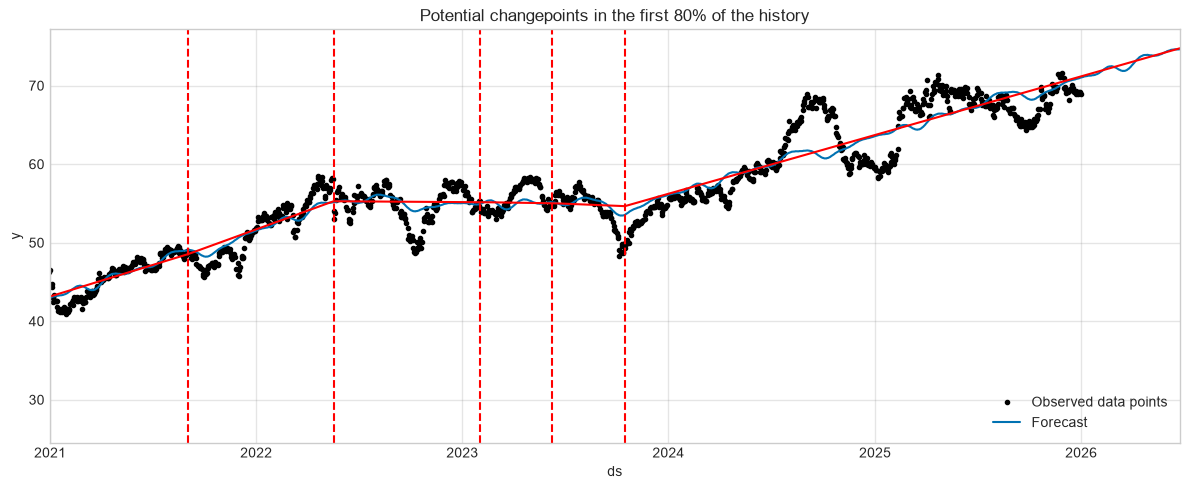

In [8]:
default_figure = final_model.plot(
    forecast_df,
    uncertainty=False,
    figsize=(12, 5),
    include_legend=True,
)
default_axis = default_figure.axes[0]
add_changepoints_to_plot(default_axis, final_model, forecast_df)
default_axis.set(
    title="Potential changepoints in the first 80% of the history",
    xlim=(prophet_data["ds"].max() - pd.DateOffset(years=5), future_dates["ds"].max()),
)
default_figure.tight_layout()
plt.show()

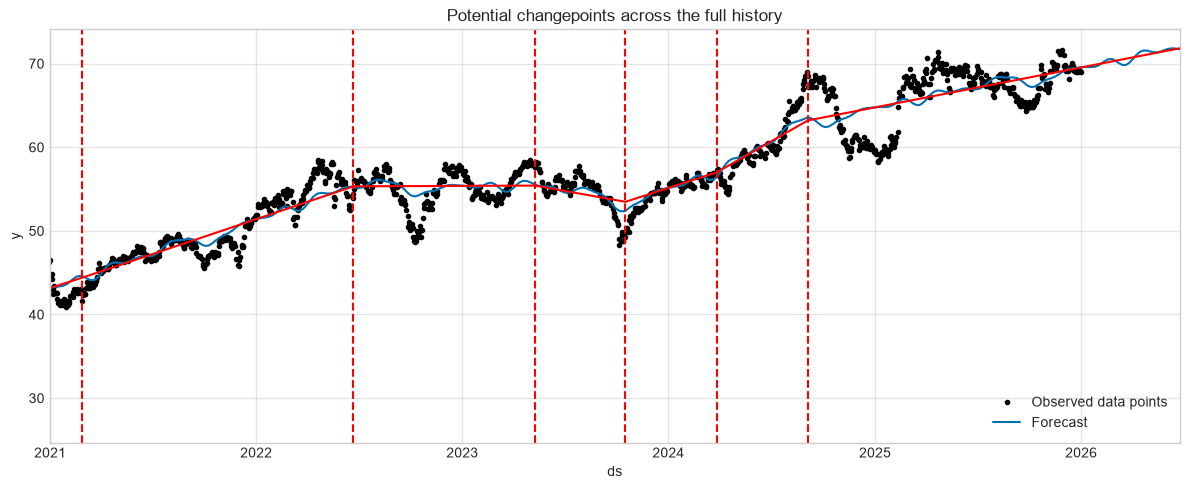

,candidate_count,latest_candidate,last_yhat
range=0.8,25,2023-10-16,74.614977
range=1.0,25,2025-12-31,71.712626


In [9]:
full_range_model = fit_prophet(prophet_data, changepoint_range=1.0)
np.random.seed(RANDOM_SEED)
full_range_forecast = full_range_model.predict(future_dates)

full_range_figure = full_range_model.plot(
    full_range_forecast,
    uncertainty=False,
    figsize=(12, 5),
    include_legend=True,
)
full_range_axis = full_range_figure.axes[0]
add_changepoints_to_plot(full_range_axis, full_range_model, full_range_forecast)
full_range_axis.set(
    title="Potential changepoints across the full history",
    xlim=(prophet_data["ds"].max() - pd.DateOffset(years=5), future_dates["ds"].max()),
)
full_range_figure.tight_layout()
plt.show()

pd.DataFrame(
    {
        "candidate_count": [len(final_model.changepoints), len(full_range_model.changepoints)],
        "latest_candidate": [final_model.changepoints.max(), full_range_model.changepoints.max()],
        "last_yhat": [forecast_df["yhat"].iloc[-1], full_range_forecast["yhat"].iloc[-1]],
    },
    index=["range=0.8", "range=1.0"],
)